# E2 / CV — os cinco métodos sob CV 5-fold por paciente

Etapa **anterior** ao treino final (`e2_01_ssl.ipynb`), no molde do `e1_02_cv.ipynb`. Mesmos métodos (+ `mt-temporal-prev3`, vizinho $t-3$, e `dtc-trus`, cuja etapa 1 é o `supervised` do mesmo fold), mesmos
lotes (8 rotulados + 8 centrais não rotulados) e mesmos lr/wd congelados do E1.

**Rodada k:** treina nos folds $\neq k$ do desenvolvimento (rótulos + todo frame nunca anotado **só desses
vídeos**), escolhe o checkpoint pela validação fixa (`val/dice_patient`) e avalia no fold $k$
(`eval_set = cv`). O teste INCA e o UNM não são carregados: eles ficam para o treino final.

**Agregação:** frames → paciente → média dos pacientes do fold → média ± desvio (ddof=1) entre os 5 folds.
As comparações entre métodos são **pareadas por fold** (mesmos pacientes retidos, mesma seed).

> O desvio entre folds mistura a sensibilidade à partição com o ruído do próprio treino (re-runs idênticos
> já divergiram ~0,10 de Dice no X1). Os folds compartilham pacientes de treino, então não são réplicas
> independentes: o desvio **não** é um erro-padrão.

Config: `configs/sweep/e2-cv.yaml`; lógica: `src/sweeps/e2.py` (`E2CVSweep`).

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../../")

import matplotlib.pyplot as plt
import pandas as pd

from src.evaluation import METRIC_NAMES, aggregate_per_patient, paired_fold_differences, summarize_over_folds
from src.sweep import Sweep, submit_sweep, sweep_status, watch_sweep

SWEEP_CONFIG = "configs/sweep/e2-cv.yaml"

# Grade. Trocar aqui NAO edita o YAML: vira `--set axes.<eixo>=[...]` no processo do tmux.
ARCHS = ["deeplabv3plus"]
POLICIES = ["global"]                # ["global", "same_video"] para comparar a origem dos nao rotulados
SEEDS = [42]
REFERENCE_METHOD = "supervised"
METHOD_ORDER = ["supervised", "fixmatch", "meanteacher", "mt-temporal-prev", "mt-temporal-prev3", "mt-temporal-bi", "dtc-trus"]

OVERRIDES = {"axes.arch": ARCHS, "axes.unlabeled_policy": POLICIES, "axes.seed": SEEDS}
sweep = Sweep(SWEEP_CONFIG, overrides=OVERRIDES)
sweep.plan_summary()

/home/caioseda/miniconda3/envs/vfss/lib/python3.12/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


,run_id,seed,arch,unlabeled_policy,fold,method,status
0,deeplabv3plus-supervised-global-f0-s42,42,deeplabv3plus,global,0,supervised,done (na CSV)
1,deeplabv3plus-fixmatch-global-f0-s42,42,deeplabv3plus,global,0,fixmatch,done (na CSV)
2,deeplabv3plus-meanteacher-global-f0-s42,42,deeplabv3plus,global,0,meanteacher,done (na CSV)
3,deeplabv3plus-mt-temporal-prev-global-f0-s42,42,deeplabv3plus,global,0,mt-temporal-prev,done (na CSV)
4,deeplabv3plus-mt-temporal-bi-global-f0-s42,42,deeplabv3plus,global,0,mt-temporal-bi,done (na CSV)
5,deeplabv3plus-mt-temporal-prev3-global-f0-s42,42,deeplabv3plus,global,0,mt-temporal-prev3,done (na CSV)
6,deeplabv3plus-supervised-global-f1-s42,42,deeplabv3plus,global,1,supervised,done (na CSV)
7,deeplabv3plus-fixmatch-global-f1-s42,42,deeplabv3plus,global,1,fixmatch,done (na CSV)
8,deeplabv3plus-meanteacher-global-f1-s42,42,deeplabv3plus,global,1,meanteacher,done (na CSV)
9,deeplabv3plus-mt-temporal-prev-global-f1-s42,42,deeplabv3plus,global,1,mt-temporal-prev,done (na CSV)


## Execução

O treino roda numa sessão tmux (`e2-cv`); fechar o notebook não o interrompe. 30 runs por (arch, política, seed).

In [3]:
sweep_status(SWEEP_CONFIG, overrides=OVERRIDES)

,run_id,seed,arch,unlabeled_policy,fold,method,status
0,deeplabv3plus-supervised-global-f0-s42,42,deeplabv3plus,global,0,supervised,done (na CSV)
1,deeplabv3plus-fixmatch-global-f0-s42,42,deeplabv3plus,global,0,fixmatch,done (na CSV)
2,deeplabv3plus-meanteacher-global-f0-s42,42,deeplabv3plus,global,0,meanteacher,done (na CSV)
3,deeplabv3plus-mt-temporal-prev-global-f0-s42,42,deeplabv3plus,global,0,mt-temporal-prev,done (na CSV)
4,deeplabv3plus-mt-temporal-bi-global-f0-s42,42,deeplabv3plus,global,0,mt-temporal-bi,done (na CSV)
5,deeplabv3plus-mt-temporal-prev3-global-f0-s42,42,deeplabv3plus,global,0,mt-temporal-prev3,done (na CSV)
6,deeplabv3plus-supervised-global-f1-s42,42,deeplabv3plus,global,1,supervised,done (na CSV)
7,deeplabv3plus-fixmatch-global-f1-s42,42,deeplabv3plus,global,1,fixmatch,done (na CSV)
8,deeplabv3plus-meanteacher-global-f1-s42,42,deeplabv3plus,global,1,meanteacher,done (na CSV)
9,deeplabv3plus-mt-temporal-prev-global-f1-s42,42,deeplabv3plus,global,1,mt-temporal-prev,done (na CSV)


In [4]:
# submit_sweep(SWEEP_CONFIG, overrides=OVERRIDES)

In [5]:
watch_sweep(SWEEP_CONFIG, overrides=OVERRIDES)

e2-cv: 30/30 celulas concluidas (11:08:03)
                                       run_id  seed          arch unlabeled_policy  fold            method        status
       deeplabv3plus-supervised-global-f0-s42    42 deeplabv3plus           global     0        supervised done (na CSV)
         deeplabv3plus-fixmatch-global-f0-s42    42 deeplabv3plus           global     0          fixmatch done (na CSV)
      deeplabv3plus-meanteacher-global-f0-s42    42 deeplabv3plus           global     0       meanteacher done (na CSV)
 deeplabv3plus-mt-temporal-prev-global-f0-s42    42 deeplabv3plus           global     0  mt-temporal-prev done (na CSV)
   deeplabv3plus-mt-temporal-bi-global-f0-s42    42 deeplabv3plus           global     0    mt-temporal-bi done (na CSV)
deeplabv3plus-mt-temporal-prev3-global-f0-s42    42 deeplabv3plus           global     0 mt-temporal-prev3 done (na CSV)
       deeplabv3plus-supervised-global-f1-s42    42 deeplabv3plus           global     1        supervised don

## Resultados por fold

In [6]:
results = sweep.load_results()
results = results[results.arch.isin(ARCHS) & results.unlabeled_policy.isin(POLICIES) & results.seed.isin(SEEDS)]
assert set(results.eval_set) == {"cv"}, "o CV so pode ter linhas do fold retido"

BY = ["arch", "unlabeled_policy", "method"]
per_fold = aggregate_per_patient(results, group_columns=BY + ["fold", "seed"])
per_fold["method"] = pd.Categorical(per_fold["method"], METHOD_ORDER, ordered=True)
per_fold.pivot_table(index="fold", columns="method", values="dice", observed=True).round(4)

method,supervised,fixmatch,meanteacher,mt-temporal-prev,mt-temporal-prev3,mt-temporal-bi
fold,,,,,,
0,0.8585,0.8511,0.8572,0.8552,0.8587,0.8590
1,0.8697,0.8704,0.8789,0.8727,0.8726,0.8751
2,0.8718,0.8572,0.8698,0.8706,0.8654,0.8658
3,0.8392,0.8467,0.8479,0.8391,0.8411,0.8425
4,0.8505,0.8592,0.8540,0.8572,0.8498,0.8506


## Média ± desvio entre folds

In [7]:
summary = summarize_over_folds(per_fold, BY).sort_values(BY)
table = summary[BY + ["n_folds"]].copy()
for metric in METRIC_NAMES:
    table[metric] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(summary[f"{metric}_mean"], summary[f"{metric}_std"])]
table.reset_index(drop=True)

,arch,unlabeled_policy,method,n_folds,dice,iou,assd,hd95
0,deeplabv3plus,global,supervised,5,0.8579 ± 0.0136,0.7566 ± 0.0189,1.4374 ± 0.2033,6.0792 ± 0.8607
1,deeplabv3plus,global,fixmatch,5,0.8569 ± 0.0090,0.7545 ± 0.0126,1.4029 ± 0.0939,5.8454 ± 0.6156
2,deeplabv3plus,global,meanteacher,5,0.8616 ± 0.0126,0.7625 ± 0.0177,1.3225 ± 0.0933,5.3803 ± 0.4775
3,deeplabv3plus,global,mt-temporal-prev,5,0.8590 ± 0.0136,0.7585 ± 0.0190,1.3756 ± 0.1062,5.6234 ± 0.4974
4,deeplabv3plus,global,mt-temporal-prev3,5,0.8575 ± 0.0125,0.7562 ± 0.0166,1.3784 ± 0.1368,5.5886 ± 0.5731
5,deeplabv3plus,global,mt-temporal-bi,5,0.8586 ± 0.0127,0.7585 ± 0.0175,1.3571 ± 0.1069,5.5710 ± 0.3997


## Diferença pareada por fold contra o supervisionado

Positivo = maior que o supervisionado (melhor para Dice/IoU, pior para ASSD/HD95). `vitórias` conta em
quantos folds o método supera a referência em Dice.

In [8]:
diffs = paired_fold_differences(per_fold, by="method", reference=REFERENCE_METHOD,
                                group_columns=["arch", "unlabeled_policy", "seed"])
display(diffs.pivot_table(index="fold", columns="method", values="dice", observed=True).round(4))

diff_summary = summarize_over_folds(diffs, BY)
wins = diffs.assign(win=diffs.dice > 0).groupby(BY, observed=True).win.sum().rename("vitórias (Dice)")
diff_summary = diff_summary.merge(wins.reset_index(), on=BY)
diff_summary[BY + ["n_folds", "vitórias (Dice)", "dice_mean", "dice_std", "hd95_mean", "hd95_std"]].round(4)

method,fixmatch,meanteacher,mt-temporal-prev,mt-temporal-prev3,mt-temporal-bi
fold,,,,,
0,-0.0074,-0.0012,-0.0033,0.0002,0.0006
1,0.0007,0.0093,0.0031,0.0029,0.0055
2,-0.0146,-0.0020,-0.0012,-0.0064,-0.0059
3,0.0074,0.0087,-0.0002,0.0018,0.0033
4,0.0087,0.0034,0.0067,-0.0008,0.0000


,arch,unlabeled_policy,method,n_folds,vitórias (Dice),dice_mean,dice_std,hd95_mean,hd95_std
0,deeplabv3plus,global,fixmatch,5,3,-0.0010,0.0099,-0.2338,0.8032
1,deeplabv3plus,global,meanteacher,5,3,0.0036,0.0053,-0.6988,0.6244
2,deeplabv3plus,global,mt-temporal-prev,5,2,0.0010,0.0039,-0.4557,0.7494
3,deeplabv3plus,global,mt-temporal-prev3,5,3,-0.0004,0.0036,-0.4906,0.4279
4,deeplabv3plus,global,mt-temporal-bi,5,4,0.0007,0.0043,-0.5082,0.6783


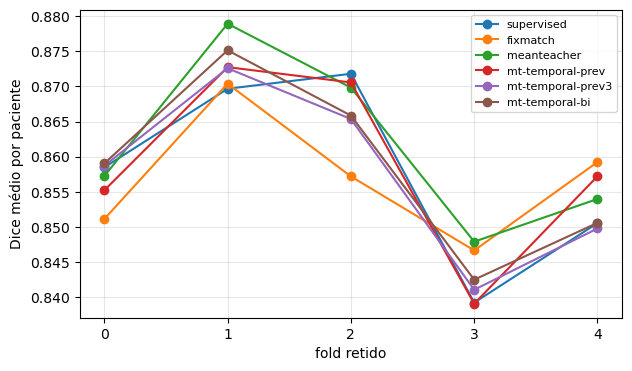

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
for method, group in per_fold.groupby("method", observed=True):
    group = group.sort_values("fold")
    ax.plot(group.fold, group.dice, marker="o", label=method)
ax.set_xlabel("fold retido"); ax.set_ylabel("Dice médio por paciente"); ax.set_xticks(range(5))
ax.legend(fontsize=8); ax.grid(alpha=0.3)

## Custo por run (média entre folds)

In [10]:
resources = sweep.plan.load_resources()
if len(resources):
    resources = resources[resources.arch.isin(ARCHS) & resources.unlabeled_policy.isin(POLICIES) & resources.seed.isin(SEEDS)]
    cols = [c for c in ["fit_wall_s", "total_fit_wall_s", "s_per_step_mean", "data_wait_frac", "vram_train_peak_gb", "best_step"] if c in resources]
    display(resources.groupby(BY)[cols].agg(["mean", "std"]).round(3))

fit_wall_s           \
                                                       mean      std   
arch          unlabeled_policy method                                  
deeplabv3plus global           fixmatch             634.373   47.697   
                               meanteacher          382.228  100.979   
                               mt-temporal-bi       381.360  179.438   
                               mt-temporal-prev     370.199  200.557   
                               mt-temporal-prev3    376.196  158.855   
                               supervised           426.334   82.409   

                                                 s_per_step_mean         \
                                                            mean    std   
arch          unlabeled_policy method                                     
deeplabv3plus global           fixmatch                    0.149  0.001   
                               meanteacher                 0.118  0.002   
                               mt-temporal-bi              0.205  0.003   
                               mt-temporal-prev            0.159  0.005   
                               mt-temporal-prev3           0.159  0.002   
                               supervised                  0.105  0.010   

                                                 data_wait_frac         \
                                                           mean    std   
arch          unlabeled_policy method                                    
deeplabv3plus global           fixmatch                   0.179  0.006   
                               meanteacher                0.342  0.006   
                               mt-temporal-bi             0.551  0.004   
                               mt-temporal-prev           0.439  0.016   
                               mt-temporal-prev3          0.440  0.009   
                               supervised                 0.323  0.077   

                                                 vram_train_peak_gb         \
                                                               mean    std   
arch          unlabeled_policy method                                        
deeplabv3plus global           fixmatch                       2.178  0.046   
                               meanteacher                    1.874  0.002   
                               mt-temporal-bi                 2.395  0.077   
                               mt-temporal-prev               2.093  0.094   
                               mt-temporal-prev3              2.193  0.003   
                               supervised                     1.698  0.093   

                                                 best_step            
                                                      mean       std  
arch          unlabeled_policy method                                 
deeplabv3plus global           fixmatch             3800.0   273.861  
                               meanteacher          2800.0   758.288  
                               mt-temporal-bi       1700.0   836.660  
                               mt-temporal-prev     2100.0  1193.734  
                               mt-temporal-prev3    2100.0   894.427  
                               supervised           3500.0   707.107